# **Lab project 3: Domain Alignment with GANs for robust classifier generalization**

<p style="color: #1565C0;"><strong>Student: Luis Manuel García Muñoz</strong></p>

**Pablo Martínez Olmos, Vanessa Gómez Verdejo,  Alejandro Lancho Serrano, Emilio Parrado Hernández**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='https://upload.wikimedia.org/wikipedia/commons/8/88/Acronimo_nombre3l.jpg' width=300 />


In this notebook, you will deploy domain alignment using a **CycleGAN-style architecture** on **tabular data**, followed by downstream evaluation with classical classifiers.

The goal is to show how data coming from two different domains (A and B) can be aligned *before* training a classifier, improving generalization under domain shift.

---

## 1. Problem setup

We consider a **binary classification problem on tabular data**. The original dataset is split into two domains:

- **Domain A**: clean data (reference domain)
- **Domain B**: a synthetically shifted version of A, obtained via
  - deterministic smooth nonlinear transformations
  - additive noise and feature corruption

The task is to **undo the domain shift** in B using a GAN-based alignment model.


## 2. Imports and reproducibility

We load a binary classification dataset from the UCI repository (Breast Cancer Wisconsin Diagnostic).

The dataset consists of:
- numeric features only
- binary target labels

In [32]:
# pip install -q scikit-learn pandas

import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from scipy.stats import wasserstein_distance_nd
from sklearn.metrics import RocCurveDisplay
import itertools

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset



ds = load_breast_cancer(as_frame=True)
X = ds.data
y = ds.target  # 0/1 labels

print("X shape:", X.shape)
print("y value counts:\n", y.value_counts())
print(X.head())

X shape: (569, 30)
y value counts:
 target
1    357
0    212
Name: count, dtype: int64
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   me

In [33]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print(f"Using device: {device}")

Using device: mps


## 4. Domain construction (A vs B)

The dataset is randomly split into two equal parts:

- **Set A**: used as-is
- **Set B**: transformed to simulate a domain shift

All features are standardized using statistics computed **only from A**.

### 4.1 Deterministic smooth transformation

Let $x \in \mathbb{R}^d$ be a standardized sample from domain \(B\).
We apply a deterministic, smooth feature warp
$$
x^{\text{det}} = T_{\text{det}}(x),
$$
defined componentwise as
$$
x^{\text{det}}_j
= x_j
+ \alpha_j \tanh(\beta_j x_j + \phi_j)
+ 0.05\,s\,\tanh(x_{j-1}),
$$
with wrap-around indexing for $x_{j-1}$. The parameters are fixed per feature:
$$
\alpha_j = s\left(0.15 + 0.10\sin(0.7j)\right),\quad
\beta_j  = 0.8 + 0.3\cos(0.5j),\quad
\phi_j   = 0.2\sin(1.3j),
$$

where $s$ is the warping strength. This introduces a structured, smooth, nonlinear domain shift.


### 4.2 Stochastic corruption

After the deterministic warp, we apply stochastic perturbations:
$$
x^{B} = \text{Dropout}\big(m \odot x^{\text{det}} + b + \epsilon\big),
$$
where
$$
m_j \sim \mathcal{N}(1,\sigma_{\text{scale}}^2),\quad
b_j \sim \mathcal{N}(0,\sigma_{\text{shift}}^2),\quad
\epsilon_{ij} \sim \mathcal{N}(0,\sigma_{\text{gauss}}^2).
$$

Feature dropout is applied independently with probability $p_{\text{drop}}$. This combination of **systematic nonlinear distortion** and **random corruption** produces a challenging but realistic domain shift.



### Domain shift parameters (summary)

| Component | Parameter | Value |
|---------|-----------|-------|
| Split | Train/test ratio | 50% A / 50% B |
| Standardization | Statistics source | Set A only |
| Deterministic warp | Strength $s$ | 0.8 |
| Deterministic warp | $\alpha_j$ | $0.8(0.15 + 0.10\sin(0.7j))$ |
| Deterministic warp | $\beta_j$ | $0.8 + 0.3\cos(0.5j)$ |
| Deterministic warp | $\phi_j$ | $0.2\sin(1.3j)$ |
| Cross-feature term | Neighbor weight | $0.05\,s = 0.04$ |
| Gaussian noise | $\sigma_{\text{gauss}}$ | 0.55 |
| Feature scaling | $\sigma_{\text{scale}}$ | 0.80 |
| Feature shifting | $\sigma_{\text{shift}}$ | 0.80 |
| Feature dropout | $p_{\text{drop}}$ | 0.60 |

---


<p style="color: #1565C0;">I split the data into clean domain A and corrupted domain B. I standardize both using A only and keep the original class labels.</p>


In [34]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ---------------------------
# 1) Split into Set A / Set B
# ---------------------------
XA_df, XB_df, yA_s, yB_s = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=y
)

# ---------------------------
# 2) Standardize using ONLY Set A stats
# ---------------------------
scaler = StandardScaler()
XA = scaler.fit_transform(XA_df.values.astype(np.float32))
XB = scaler.transform(XB_df.values.astype(np.float32))

rng = np.random.default_rng(42)

# ---------------------------
# 3) Deterministic smooth transformation (domain B)
# ---------------------------
def smooth_domain_transform(XB_std: np.ndarray, strength: float = 0.8) -> np.ndarray:
    d = XB_std.shape[1]
    X = XB_std

    i = np.arange(d, dtype=np.float32)
    alpha = strength * (0.15 + 0.10 * np.sin(0.7 * i))
    beta  = 0.8 + 0.3 * np.cos(0.5 * i)
    phase = 0.2 * np.sin(1.3 * i)

    alpha = alpha[None, :]
    beta  = beta[None, :]
    phase = phase[None, :]

    X_warp = X + alpha * np.tanh(beta * X + phase)

    # cross-feature smooth interaction
    X_roll = np.roll(X, shift=1, axis=1)
    X_warp += (strength * 0.05) * np.tanh(X_roll)

    return X_warp.astype(np.float32)

XB_det = smooth_domain_transform(XB)

# ---------------------------
# 4) Stochastic corruption (domain B)
# ---------------------------
sigma_gauss = 0.55
scale_jitter = 0.80
shift_jitter = 0.80
p_dropout = 0.60

gauss = rng.normal(0.0, sigma_gauss, size=XB_det.shape).astype(np.float32)
mult  = rng.normal(1.0, scale_jitter, size=(1, XB_det.shape[1])).astype(np.float32)
shift = rng.normal(0.0, shift_jitter, size=(1, XB_det.shape[1])).astype(np.float32)

XB_noisy = XB_det * mult + shift + gauss

if p_dropout > 0:
    mask = rng.random(XB_noisy.shape) < p_dropout
    XB_noisy[mask] = 0.0

# Labels unchanged
yA = yA_s.values.astype(np.int64)
yB = yB_s.values.astype(np.int64)

print("Set A:", XA.shape, "labels:", np.bincount(yA))
print("Set B (det + noisy):", XB_noisy.shape, "labels:", np.bincount(yB))


Set A: (284, 30) labels: [106 178]
Set B (det + noisy): (285, 30) labels: [106 179]


## 5. Visualizing domain shift

Analyze statistically both domains and visualize them with TSNE. Evaluate the sample [Wasserstein_distance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html) between both domains.

<p style="color: #1565C0;">I visualize the domain shift with a shared t-SNE embedding and quantify it using the multidimensional Wasserstein distance.</p>


Joint Wasserstein-1 distance: 5.540907652823761


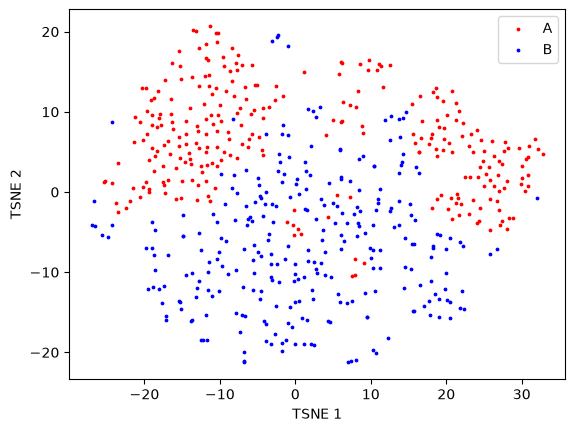

In [35]:
# COMPLETE

num_A = XA.shape[0]

tsne = TSNE(n_components=2, perplexity=30, random_state=42)

w_before = wasserstein_distance_nd(XA, XB_noisy)
print("Joint Wasserstein-1 distance:", w_before)

X_joined = np.concatenate([XA, XB_noisy], axis=0)


X_tsne = tsne.fit_transform(X_joined)



plt.scatter(X_tsne[:num_A,0], X_tsne[:num_A,1], c='r', label='A', s =3)
plt.scatter(X_tsne[num_A:,0], X_tsne[num_A:,1], c='b', label='B', s =3)

plt.xlabel('TSNE 1')
plt.ylabel('TSNE 2')

plt.legend()


## 6. Baseline classifiers (no alignment)

We evaluate two standard classifiers:

- Logistic Regression (linear baseline)
- Gradient Boosting (nonlinear baseline)

### Experimental settings

1. **Train on A only** → test on A and B
2. **Train on B only** → test on A and B


<p style="color: #1565C0;">I train logistic regression and Gradient Boosting on each domain to establish baselines. Scores on the same training samples measure fit rather than held-out generalization.</p>


In [36]:
# COMPLETE

log_reg_trained_on_A = LogisticRegression()
log_reg_trained_on_A.fit(XA, yA)

print("Score of model trained on A on A:", log_reg_trained_on_A.score(XA, yA))
print("Score of model trained on A on B:",log_reg_trained_on_A.score(XB_noisy, yB))

log_reg_trained_on_B = LogisticRegression()
log_reg_trained_on_B.fit(XB_noisy, yB)
print("Score of B on B:", log_reg_trained_on_B.score(XB_noisy, yB))
print("Score of B on A:", log_reg_trained_on_B.score(XA, yA))



Score of model trained on A on A: 0.9929577464788732
Score of model trained on A on B: 0.8491228070175438
Score of B on B: 0.9192982456140351
Score of B on A: 0.9014084507042254


In [37]:
# Gradient Boosting baseline (no alignment)

gb_trained_on_A = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    min_samples_split=2,
    min_samples_leaf=1,
    subsample=1.0,
    max_features=None,
    loss="log_loss",
    random_state=42,
)
gb_trained_on_A.fit(XA, yA)

print("Score of model trained on A on A:", gb_trained_on_A.score(XA, yA))
print("Score of model trained on A on B:", gb_trained_on_A.score(XB_noisy, yB))

gb_trained_on_B = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    min_samples_split=2,
    min_samples_leaf=1,
    subsample=1.0,
    max_features=None,
    loss="log_loss",
    random_state=42,
)
gb_trained_on_B.fit(XB_noisy, yB)

print("Score of B on B:", gb_trained_on_B.score(XB_noisy, yB))
print("Score of B on A:", gb_trained_on_B.score(XA, yA))


Score of model trained on A on A: 1.0
Score of model trained on A on B: 0.6736842105263158
Score of B on B: 0.9894736842105263
Score of B on A: 0.9119718309859155


## 7. ROC analysis (before alignment)

Receiver Operating Characteristic (ROC) curves are plotted for both domains.

Expected outcome:
- Good performance on A
- Significant degradation on B due to domain shift

<p style="color: #1565C0;">I compare ROC curves on A and B for classifiers trained on A to assess the effect of the domain shift.</p>


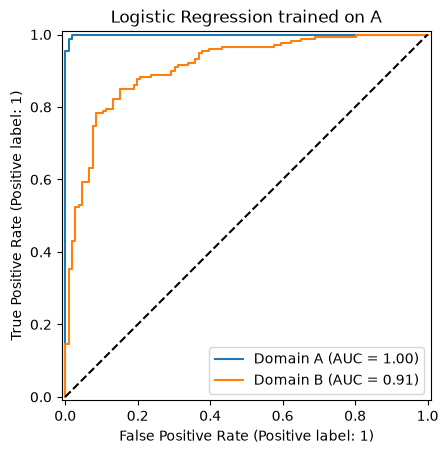

In [38]:


fig, ax = plt.subplots()
RocCurveDisplay.from_estimator(log_reg_trained_on_A, XA, yA, name="Domain A", ax=ax)
RocCurveDisplay.from_estimator(log_reg_trained_on_A, XB_noisy, yB, name="Domain B", ax=ax)
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Logistic Regression trained on A")
plt.show()


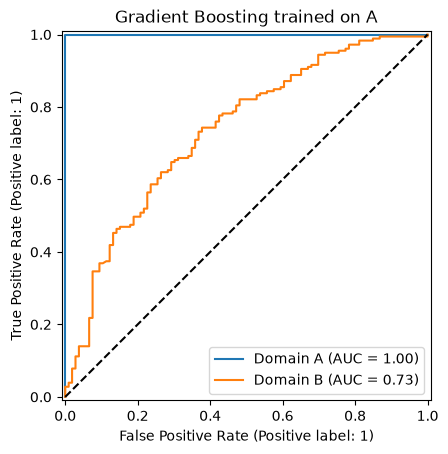

In [39]:


fig, ax = plt.subplots()
RocCurveDisplay.from_estimator(gb_trained_on_A, XA, yA, name="Domain A", ax=ax)
RocCurveDisplay.from_estimator(gb_trained_on_A, XB_noisy, yB, name="Domain B", ax=ax)
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Gradient Boosting trained on A")
plt.show()


## 8. GAN-based domain alignment

We implement a **CycleGAN-style architecture for tabular data**:

- Generators:
  - G_AB: maps A → B
  - G_BA: maps B → A
- Discriminators:
  - D_A: real vs fake A
  - D_B: real vs fake B

During training, we log and visualize:

- discriminator losses
- generator adversarial loss
- cycle consistency loss
- identity loss

This helps diagnose instability or mode collapse.

In [40]:
X = torch.tensor(XA, dtype=torch.float32)
Y = torch.tensor(XB_noisy, dtype=torch.float32)
loader_X = DataLoader(TensorDataset(X), batch_size=16, shuffle=True)
loader_Y = DataLoader(TensorDataset(Y), batch_size=16, shuffle=True)

<p style="color: #1565C0;">I use residual generators (30 → 32 → 32 → 30) initialized to the identity and critics (30 → 32 → 16 → 1). This lets the generators start by preserving the input and learn corrections.</p>


In [41]:
# Residual generators start at the identity; fix initialization for reproducibility.
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

class MLPGenerator(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        if input_dim != output_dim:
            raise ValueError("Residual generators require equal input/output dimensions")
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, output_dim)
        )
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, x):
        return x + self.net(x)

class MLPDiscriminator(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1)  # No sigmoid for WGAN
        )

    def forward(self, x):
        return self.net(x)

G_XtoY = MLPGenerator(X.shape[1], XB_noisy.shape[1]).to(device)
G_YtoX = MLPGenerator(Y.shape[1], XA.shape[1]).to(device)
D_X = MLPDiscriminator(X.shape[1]).to(device)
D_Y = MLPDiscriminator(Y.shape[1]).to(device)

# SECTION 3: Losses and Optimizers
cycle_criterion = nn.L1Loss()
identity_criterion = nn.L1Loss()

g_params = itertools.chain(G_XtoY.parameters(), G_YtoX.parameters())
optimizer_G = optim.RMSprop(g_params, lr=0.0001)
optimizer_D_X = optim.RMSprop(D_X.parameters(), lr=0.0001)
optimizer_D_Y = optim.RMSprop(D_Y.parameters(), lr=0.0001)

<p style="color: #1565C0;">I train both mappings with WGAN adversarial losses, cycle consistency (weight 10) and identity regularization (weight 5). I use a learning rate of 0.0001 to make updates more gradual; B labels are not used.</p>


In [42]:
# SECTION 4: Training
EPOCHS = 100
clip_value = 0.2
critic_iters = 10
lambda_cycle = 10.0
lambda_identity = 5.0

G_XtoY.train()
G_YtoX.train()

# Initialize loss logs
losses_G = []
losses_D_X = []
losses_D_Y = []
losses_cycle = []
losses_identity = []

for epoch in range(EPOCHS):
    for (x_batch,), (y_batch,) in zip(loader_X, loader_Y):
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        # ----------------------
        #  Train Discriminators
        # ----------------------
        for _ in range(critic_iters):
            # Discriminator X
            optimizer_D_X.zero_grad()
            fake_X = G_YtoX(y_batch).detach()
            loss_D_X = -torch.mean(D_X(x_batch)) + torch.mean(D_X(fake_X))
            loss_D_X.backward()
            optimizer_D_X.step()
            for p in D_X.parameters():
                p.data.clamp_(-clip_value, clip_value)

            # Discriminator Y
            optimizer_D_Y.zero_grad()
            fake_Y = G_XtoY(x_batch).detach()
            loss_D_Y = -torch.mean(D_Y(y_batch)) + torch.mean(D_Y(fake_Y))
            loss_D_Y.backward()
            optimizer_D_Y.step()
            for p in D_Y.parameters():
                p.data.clamp_(-clip_value, clip_value)

        # ----------------------
        #  Train Generators
        # ----------------------
        optimizer_G.zero_grad()
        fake_Y = G_XtoY(x_batch)
        fake_X = G_YtoX(y_batch)

        loss_G_XtoY = -torch.mean(D_Y(fake_Y))
        loss_G_YtoX = -torch.mean(D_X(fake_X))

        recov_X = G_YtoX(fake_Y)
        recov_Y = G_XtoY(fake_X)
        loss_cycle = cycle_criterion(recov_X, x_batch) + cycle_criterion(recov_Y, y_batch)

        same_X = G_YtoX(x_batch)
        same_Y = G_XtoY(y_batch)
        loss_identity = identity_criterion(same_X, x_batch) + identity_criterion(same_Y, y_batch)

        loss_G = loss_G_XtoY + loss_G_YtoX + lambda_cycle * loss_cycle + lambda_identity * loss_identity
        loss_G.backward()
        optimizer_G.step()

        # Log losses
        losses_G.append(loss_G.item())
        losses_D_X.append(loss_D_X.item())
        losses_D_Y.append(loss_D_Y.item())
        losses_cycle.append(loss_cycle.item())
        losses_identity.append(loss_identity.item())

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}: G={loss_G.item():.4f}, D_X={loss_D_X.item():.4f}, D_Y={loss_D_Y.item():.4f}")


Epoch 5: G=3.1301, D_X=-1.6583, D_Y=-1.4427
Epoch 10: G=7.0361, D_X=-3.9230, D_Y=-3.2924
Epoch 15: G=10.0001, D_X=-3.4280, D_Y=-6.6728
Epoch 20: G=14.2365, D_X=-4.1959, D_Y=-10.2039
Epoch 25: G=8.8190, D_X=-3.6807, D_Y=-3.2091
Epoch 30: G=6.9698, D_X=-3.2229, D_Y=-2.9561
Epoch 35: G=6.1127, D_X=-2.7854, D_Y=-2.5857
Epoch 40: G=4.3698, D_X=-2.2383, D_Y=0.1200
Epoch 45: G=12.3625, D_X=-6.2523, D_Y=-7.8714
Epoch 50: G=3.7760, D_X=-2.6221, D_Y=-0.3412
Epoch 55: G=9.5934, D_X=-5.3927, D_Y=-6.5447
Epoch 60: G=6.9921, D_X=-4.3317, D_Y=-3.6926
Epoch 65: G=10.7174, D_X=-6.4919, D_Y=-5.4818
Epoch 70: G=8.5540, D_X=-4.5086, D_Y=-5.5099
Epoch 75: G=6.5484, D_X=-3.6716, D_Y=-2.4007
Epoch 80: G=5.6549, D_X=-3.0340, D_Y=-1.0846
Epoch 85: G=7.6649, D_X=-3.7771, D_Y=-1.3200
Epoch 90: G=9.1660, D_X=-3.4747, D_Y=-0.1764
Epoch 95: G=11.0162, D_X=-4.7773, D_Y=-3.4199
Epoch 100: G=6.8078, D_X=-2.6143, D_Y=-0.5140


<p style="color: #1565C0;">I plot the training losses to monitor the adversarial and reconstruction objectives. These curves alone do not establish whether classification improves.</p>


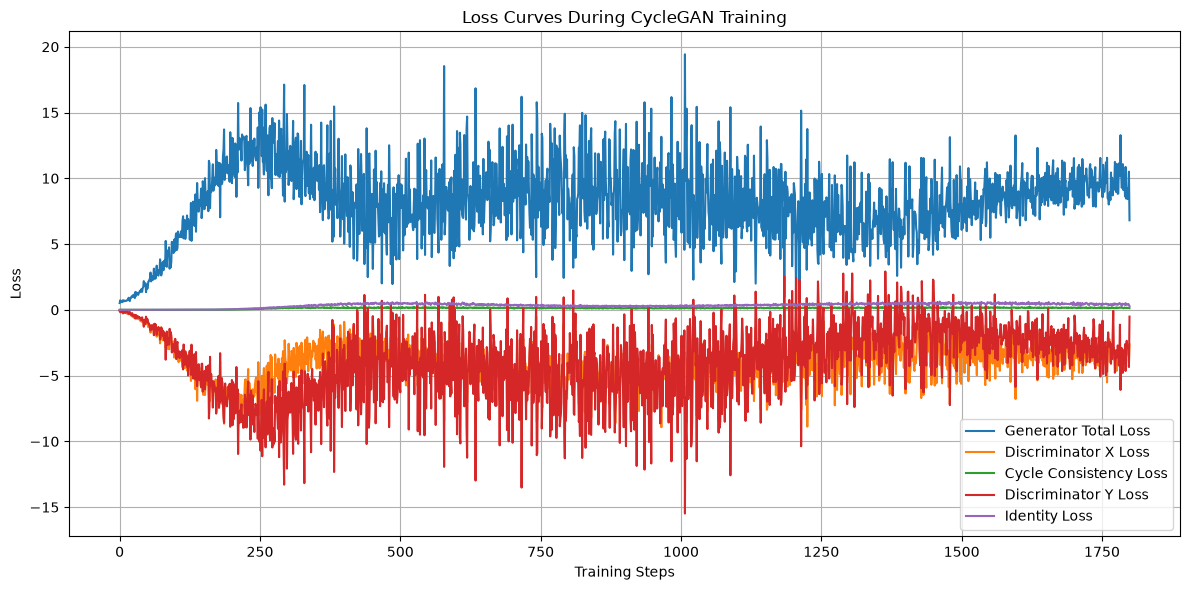

In [43]:
# SECTION 6: Plot Loss Curves
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(losses_G, label='Generator Total Loss')
plt.plot(losses_D_X, label='Discriminator X Loss')
plt.plot(losses_cycle, label='Cycle Consistency Loss')
plt.plot(losses_D_Y, label='Discriminator Y Loss')
plt.plot(losses_identity, label='Identity Loss')

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Loss Curves During CycleGAN Training")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. Visualize the aligned domain

Use TSNE and evaluate the Wasserstein distance between A and B (aligned with CycleGAN)

<p style="color: #1565C0;">I map B into A with G_YtoX, keeping each sample’s label unchanged. I then compare Wasserstein distances and visualize all three distributions together.</p>


Wasserstein before: 5.5409
Wasserstein after:  4.8060


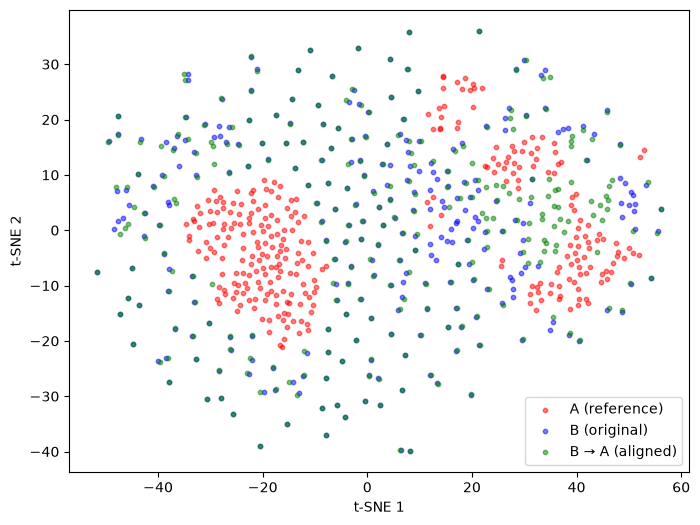

In [44]:
# COMPLETE

# Transform domain B into the reference domain A
G_YtoX.eval()

with torch.no_grad():
    XB_aligned = G_YtoX(
        torch.as_tensor(XB_noisy, dtype=torch.float32, device=device)
    ).cpu().numpy()

# Compare distances before and after alignment
w_before = wasserstein_distance_nd(XA, XB_noisy)
w_after = wasserstein_distance_nd(XA, XB_aligned)

print(f"Wasserstein before: {w_before:.4f}")
print(f"Wasserstein after:  {w_after:.4f}")

# Embed all three datasets together for a shared visualization
X_joined = np.concatenate([XA, XB_noisy, XB_aligned], axis=0)
X_tsne = TSNE(
    n_components=2, perplexity=30, random_state=42
).fit_transform(X_joined)

nA, nB = len(XA), len(XB_noisy)

plt.figure(figsize=(8, 6))
for points, label, color in [
    (X_tsne[:nA], "A (reference)", "red"),
    (X_tsne[nA:nA+nB], "B (original)", "blue"),
    (X_tsne[nA+nB:], "B → A (aligned)", "green"),
]:
    plt.scatter(
        points[:, 0], points[:, 1],
        label=label, c=color, s=10, alpha=0.5
    )

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend()
plt.show()

## 11. Classification after alignment

Repeat the classification experiments, now considering the aligned B domain. Analyze your results.

<p style="color: #1565C0;">I keep the classifiers trained on A fixed and compare accuracy and ROC AUC on B before and after alignment. Better distribution matching does not guarantee better classification; B was used without labels during alignment training.</p>



Logistic Regression
Original B accuracy: 0.849
Aligned B accuracy:  0.870
Original B ROC AUC: 0.910
Aligned B ROC AUC:  0.953


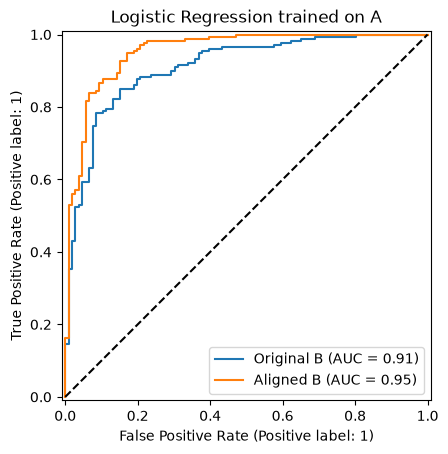


Gradient Boosting
Original B accuracy: 0.674
Aligned B accuracy:  0.821
Original B ROC AUC: 0.734
Aligned B ROC AUC:  0.925


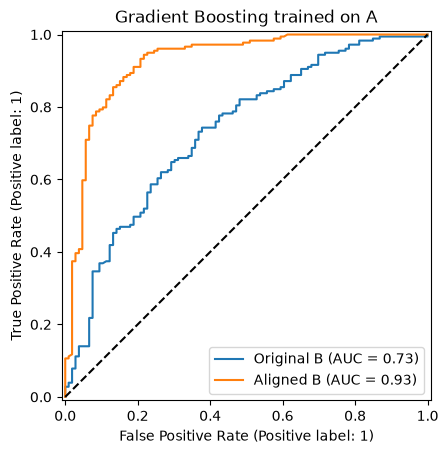

In [45]:
# Compare fixed source classifiers; B labels are used only for evaluation.
from sklearn.metrics import roc_auc_score

for name, model in [
    ("Logistic Regression", log_reg_trained_on_A),
    ("Gradient Boosting", gb_trained_on_A),
]:
    print(f"\n{name}")
    print(f"Original B accuracy: {model.score(XB_noisy, yB):.3f}")
    print(f"Aligned B accuracy:  {model.score(XB_aligned, yB):.3f}")

    print(f"Original B ROC AUC: {roc_auc_score(yB, model.predict_proba(XB_noisy)[:, 1]):.3f}")
    print(f"Aligned B ROC AUC:  {roc_auc_score(yB, model.predict_proba(XB_aligned)[:, 1]):.3f}")

    fig, ax = plt.subplots()
    RocCurveDisplay.from_estimator(
        model, XB_noisy, yB, name="Original B", ax=ax
    )
    RocCurveDisplay.from_estimator(
        model, XB_aligned, yB, name="Aligned B", ax=ax
    )
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(f"{name} trained on A")
    plt.show()